In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("titanic_data_updated.csv")
df.sample(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
559,560,yes,third,"de Messemaeker, Mrs. Guillaume Joseph (Emma)",female,36.0,1,0,345572,17.4,NaN,S
872,873,no,first,"Carlsson, Mr. Frans Olof",male,33.0,0,0,695,5.0,B51 B53 B55,S


In [2]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [3]:
# checking duplicates
df.duplicated().sum()

df.drop_duplicates(inplace=True)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    object 
 2   Pclass       891 non-null    object 
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(3), object(7)
memory usage: 83.7+ KB


In [5]:
df.describe()

,PassengerId,Age,SibSp,Parch,Fare
count,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,29.699118,0.523008,0.381594,32.204208
std,257.353842,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,38.000000,1.000000,0.000000,31.000000
max,891.000000,80.000000,8.000000,6.000000,512.329200


<Axes: xlabel='Survived', ylabel='count'>

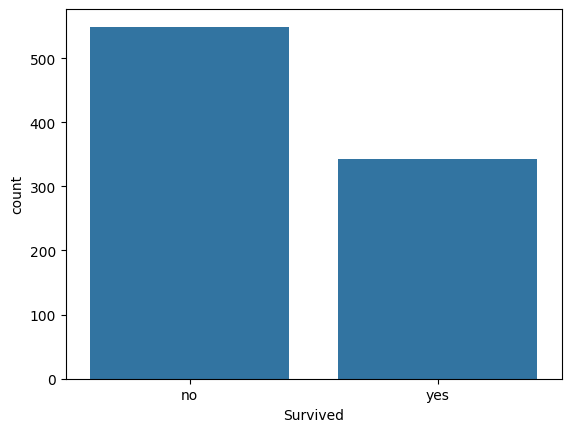

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data = df , x=df['Survived'])

In [7]:
(df['Survived'].value_counts()/len(df))*100

Survived
no     61.616162
yes    38.383838
Name: count, dtype: float64

In [8]:
df['Family_Size'] = df['SibSp'] + df['Parch'] + 1
df['Cabin'] = df['Cabin'].fillna("Missing")

df['Deck'] = df['Cabin'].astype(str).str[0]
df.sample(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Family_Size,Deck
362,363,no,third,"Barbara, Mrs. (Catherine David)",female,45.0,0,1,2691,14.4542,Missing,C,2,M
436,437,no,third,"Ford, Miss. Doolina Margaret ""Daisy""",female,21.0,2,2,W./C. 6608,34.3750,Missing,S,5,M


In [ ]:
df['Deck'].value_counts()

In [ ]:
# Separate the features (X) from the target we want to predict (y)
# We drop 'Survived' from X because that's our answer key
X = df.drop('Survived', axis=1)

# y contains only the survival status
y = df['Survived']

### Train-test split

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
# 'stratify=y' ensures both sets have a similar percentage of survivors

### Outliers handling and Data Cleaning

We use Z-scores to remove extreme outliers in `Age` and 'clip' the `Fare` column to prevent extreme values from distorting our model's learning.

In [11]:
#age
mean_age = X_train['Age'].mean()
std_age = X_train['Age'].std()

X_train['Z_score'] = (X_train['Age'] - mean_age) / std_age

musk = (abs(X_train['Z_score']) <= 3)

X_train = X_train[musk]
y_train = y_train[musk]

# fare

fare_Q1 = X_train['Fare'].quantile(0.25)
fare_Q3 = X_train['Fare'].quantile(0.75)

IQR = fare_Q3 - fare_Q1

minimum = max(0 , fare_Q1 - 1.5 * IQR)
maximum = fare_Q3 + 1.5 * IQR

X_train['Fare'] = X_train['Fare'].clip(minimum, maximum)

### **Building Preprocessing Pipelines**

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.compose import ColumnTransformer


In [13]:

#numerical
agePipe = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="mean")),
        ("scaler",StandardScaler())
    ]
)

fareFamilyPipe = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="median")),
        ("scaler",MinMaxScaler())
    ]
)

In [14]:
#* Categorical Pipelines

# categories goes one after another via stricly following the order of the input
categories = ["third","second","first"];

nominalPipe = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="most_frequent")),
        ("encoder",OneHotEncoder(sparse_output=False,drop="first",handle_unknown="ignore"))
    ]
)

ordinalPipe = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="most_frequent")),
        ("encoder",OrdinalEncoder(categories=[categories])),
        ("scaler",MinMaxScaler())
    ]
)

### Preprocessor Pipeline

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        ("agePipeline",agePipe,['Age']),
        ("fareFamPipeline",fareFamilyPipe,['Fare','Family_Size']),
        ("nominalPipeline",nominalPipe,['Embarked','Sex','Deck']),
        ("ordinalPipeline",ordinalPipe,['Pclass'])
    ],
    remainder='drop'
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('agePipeline', ...), ('fareFamPipeline', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and

## 6. Label Encoding
We convert our target variable (`yes`/`no`) into numerical values (1/0) because machine learning models require numeric inputs.

In [16]:
labelEncoder = LabelEncoder();

labelEncoder.fit(y_train)

y_train = labelEncoder.transform(y_train)
y_test = labelEncoder.transform(y_test)

### Model Training

In [17]:
from sklearn.linear_model import LogisticRegression

logisticRegresModel = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",LogisticRegression(class_weight='balanced',max_iter=1000))
    ]
)

logisticRegresModel

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('agePipeline', ...), ('fareFamPipeline', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the 

In [20]:
logisticRegresModel.fit(X_train,y_train)

print(f"Coefficients/weights:",logisticRegresModel['model'].coef_)
print(f"\nIntercept/bias:",logisticRegresModel['model'].intercept_)
print(f"Classes:",logisticRegresModel['model'].classes_)

Coefficients/weights: [[-0.5873308   0.56204461 -0.99457197 -0.32098167 -0.3412656  -2.41854631
  -0.11992536 -0.23938542  0.46586458  0.77433828  0.5040302  -0.55751189
  -0.59508309 -0.31354968  1.49423614]]

Intercept/bias: [1.436791]
Classes: [0 1]


**Prediction**

In [21]:
# Use the trained model to predict if passengers in the test set survived
y_predicted = logisticRegresModel.predict(X_test)
y_predicted

array([0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1,
       1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1,
       0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0])

In [22]:
# Get the raw probability scores (e.g., 0.85 chance of death, 0.15 chance of survival)
logisticRegresModel.predict_proba(X_test)

array([[0.85526967, 0.14473033],
       [0.92583961, 0.07416039],
       [0.76916699, 0.23083301],
       [0.92814804, 0.07185196],
       [0.37698946, 0.62301054],
       [0.44157914, 0.55842086],
       [0.25183676, 0.74816324],
       [0.59167268, 0.40832732],
       [0.48134655, 0.51865345],
       [0.78337807, 0.21662193],
       [0.8624713 , 0.1375287 ],
       [0.8168756 , 0.1831244 ],
       [0.33786725, 0.66213275],
       [0.70570024, 0.29429976],
       [0.14681691, 0.85318309],
       [0.83812407, 0.16187593],
       [0.46621184, 0.53378816],
       [0.86457955, 0.13542045],
       [0.79236436, 0.20763564],
       [0.23659906, 0.76340094],
       [0.86457955, 0.13542045],
       [0.1986873 , 0.8013127 ],
       [0.86629622, 0.13370378],
       [0.46090317, 0.53909683],
       [0.86160782, 0.13839218],
       [0.02667073, 0.97332927],
       [0.67630795, 0.32369205],
       [0.63487317, 0.36512683],
       [0.81566922, 0.18433078],
       [0.81175439, 0.18824561],
       [0.

### Evaluation

In [23]:
from sklearn.metrics import accuracy_score,precision_score,recall_score

In [ ]:
#? Accuracy - Accuracy measures the proportion of all predictions that are correct.
#* Accuracy is useful when the classes are reasonably balanced and the consequences of different mistakes are similar.

#? Precision - Precision focuses only on the observations predicted as positive
#* Precision is especially important when False Positives are costly.

#? Recall - Recall focuses on the observations that actually belong to the positive class. It's also called Sensitivity or True Positive Rate (TPR).
#* Recall is especially important when False Negatives are costly.

In [25]:
accuracy = accuracy_score(y_test,y_predicted)
print(accuracy)
precision = precision_score(y_test,y_predicted)
print(precision)
recall = recall_score(y_test,y_predicted)
print(recall)

0.7653631284916201
0.6753246753246753
0.7536231884057971
